# Improved k-clique communities — *Os Maias*

This notebook develops a weighted, overlapping version of clique percolation for the character co-occurrence network.

**Baseline idea.** A *k*-clique is a set of *k* characters in which every pair is connected. Two *k*-cliques belong to the same community when they share *k−1* characters. A community is therefore a connected chain of overlapping cliques, not necessarily a clique itself.

**Improvements implemented here**
1. **Weighted clique intensity:** a clique is retained when the geometric mean of its internal edge weights passes a continuous intensity threshold.
2. **Hierarchical refinement:** if one community dominates the covered nodes, only that community is re-percolated at larger *k*.
3. **Peripheral attachment:** uncovered characters can be attached to communities when a sufficient share of their weighted ties point into that community. These are marked separately from the clique core.
4. **Overlap-aware evaluation:** report coverage, overlap, overlapping modularity (EQ), and agreement with repeated Louvain reference partitions.

The parameters are analytical choices, not ground truth. Compare several settings and inspect the resulting members before assigning narrative meaning.

## 1. Load the network and define shared helpers

In [14]:
from pathlib import Path
from itertools import combinations
from collections import defaultdict
import math
import warnings

import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the project data without assuming the notebook's working directory.
ROOT_CANDIDATES = [Path.cwd(), *Path.cwd().parents]
def find_data_file(filename):
    candidates = []
    for root in ROOT_CANDIDATES:
        candidates += [
            root / "Data" / filename,
            root / "data" / filename,
            root / filename,
        ]
    for path in candidates:
        if path.exists():
            return path
    return None

EDGE_PATH = find_data_file("os_maias_cooccurrence_edges.csv")
NODE_PATH = find_data_file("os_maias_ground_truth_nodes.csv")

if EDGE_PATH is None:
    raise FileNotFoundError(
        "Could not find Data/os_maias_cooccurrence_edges.csv. "
        "Place the Os Maias edge CSV in a Data/ or data/ folder next to the project."
    )

def load_weighted_graph(edge_path=EDGE_PATH, node_path=NODE_PATH):
    edges = pd.read_csv(edge_path, dtype={"source": str, "target": str})
    required = {"source", "target", "weight"}
    if not required.issubset(edges.columns):
        raise ValueError(f"Edge file must contain columns {sorted(required)}")
    G = nx.Graph()
    for row in edges.itertuples(index=False):
        u, v, w = str(row.source).strip(), str(row.target).strip(), float(row.weight)
        if u == v or not np.isfinite(w) or w <= 0:
            continue
        if G.has_edge(u, v):
            G[u][v]["weight"] += w
        else:
            G.add_edge(u, v, weight=w)

    names = {}
    if node_path is not None and node_path.exists():
        nodes = pd.read_csv(node_path, dtype=str)
        if {"id", "name"}.issubset(nodes.columns):
            for node_id, name in zip(nodes["id"].str.strip(), nodes["name"]):
                G.add_node(node_id)
                if pd.notna(name) and str(name).strip():
                    names[node_id] = str(name).strip()
    for node in G:
        names.setdefault(node, str(node).replace("_", " ").title())
    return G, names

def threshold_graph(G, w_min):
    H = nx.Graph()
    H.add_nodes_from(G.nodes(data=True))
    H.add_edges_from(
        (u, v, dict(d)) for u, v, d in G.edges(data=True)
        if float(d.get("weight", 1.0)) >= w_min
    )
    return H

def transformed_weights(G, mode="log"):
    strength = dict(G.degree(weight="weight"))
    out = {}
    for u, v, d in G.edges(data=True):
        w = float(d.get("weight", 1.0))
        if mode == "raw":
            value = w
        elif mode == "log":
            value = np.log1p(w)
        elif mode == "sqrt":
            value = np.sqrt(w)
        elif mode == "cosine":
            value = w / np.sqrt(strength[u] * strength[v])
        elif mode == "none":
            value = 1.0
        else:
            raise ValueError("mode must be raw, log, sqrt, cosine or none")
        out[tuple(sorted((u, v)))] = float(value)
    return out

def with_transformed_weights(G, mode="log", attr="tw"):
    H = G.copy()
    weights = transformed_weights(G, mode)
    for u, v in H.edges:
        H[u][v][attr] = weights[tuple(sorted((u, v)))]
    return H

def cover_summary(G, cover):
    groups = [set(c) for c in cover if c]
    memberships = defaultdict(int)
    for c in groups:
        for node in c:
            memberships[node] += 1
    covered = set(memberships)
    sizes = sorted((len(c) for c in groups), reverse=True)
    return {
        "communities": len(groups),
        "coverage_pct": 100 * len(covered) / G.number_of_nodes() if G.number_of_nodes() else 0,
        "overlap_nodes": sum(v > 1 for v in memberships.values()),
        "mean_memberships": float(np.mean(list(memberships.values()))) if memberships else 0.0,
        "largest_size": sizes[0] if sizes else 0,
        "giant_fraction": sizes[0] / len(covered) if covered else 0.0,
    }

def overlapping_modularity(G, cover, weight="tw"):
    total_weight = G.size(weight=weight)
    if total_weight <= 0:
        return 0.0
    strength = dict(G.degree(weight=weight))
    memberships = defaultdict(int)
    groups = [set(c) for c in cover if c]
    for c in groups:
        for node in c:
            memberships[node] += 1
    two_w = 2 * total_weight
    eq = 0.0
    for c in groups:
        for i in c:
            for j in c:
                aij = G[i][j].get(weight, 1.0) if G.has_edge(i, j) else 0.0
                eq += (aij - strength[i] * strength[j] / two_w) / (
                    memberships[i] * memberships[j]
                )
    return float(eq / two_w)

def louvain_reference(G, seeds=(41, 42, 43, 44, 45), weight="tw"):
    return [
        [set(c) for c in nx.community.louvain_communities(G, weight=weight, seed=s)]
        for s in seeds
    ]

def _binary_entropy(p):
    if p <= 0 or p >= 1:
        return 0.0
    return float(-p*np.log2(p) - (1-p)*np.log2(1-p))

def _conditional_entropy_norm(x_cover, y_cover, n):
    vals = []
    for x in x_cover:
        hx = _binary_entropy(len(x)/n)
        if hx == 0:
            continue
        best = hx
        for y in y_cover:
            p11 = len(x & y)/n
            p10 = (len(x)-len(x&y))/n
            p01 = (len(y)-len(x&y))/n
            p00 = 1-p11-p10-p01
            if _binary_entropy(p11)+_binary_entropy(p00) <= _binary_entropy(p01)+_binary_entropy(p10):
                continue
            h_joint = -sum(p*np.log2(p) for p in (p11,p10,p01,p00) if p > 0)
            best = min(best, h_joint - _binary_entropy(len(y)/n))
        vals.append(best/hx)
    return float(np.mean(vals)) if vals else 1.0

def overlapping_nmi(cover_a, cover_b, nodes):
    universe = list(nodes)
    n = len(universe)
    if n == 0 or not cover_a or not cover_b:
        return 0.0
    a = [set(c) & set(universe) for c in cover_a if c]
    b = [set(c) & set(universe) for c in cover_b if c]
    value = 1 - 0.5*(_conditional_entropy_norm(a,b,n)+_conditional_entropy_norm(b,a,n))
    return float(np.clip(value, 0, 1))

def mean_onmi_to_louvain(cover, G, runs):
    nodes = [n for n in G if G.degree(n) > 0]
    return float(np.mean([overlapping_nmi(cover, r, nodes) for r in runs])) if runs else np.nan

G, name_map = load_weighted_graph()
print({
    "edge_file": str(EDGE_PATH),
    "node_file": str(NODE_PATH) if NODE_PATH else "not found (all edge endpoints retained)",
    "nodes": G.number_of_nodes(),
    "edges": G.number_of_edges(),
    "density": nx.density(G),
    "weight_range": (min((d["weight"] for _,_,d in G.edges(data=True)), default=0),
                     max((d["weight"] for _,_,d in G.edges(data=True)), default=0)),
})
display(pd.DataFrame([{
    "nodes": G.number_of_nodes(), "edges": G.number_of_edges(),
    "density": nx.density(G), "components": nx.number_connected_components(G),
    "isolates": nx.number_of_isolates(G)
}]))

{'edge_file': 'c:\\Users\\lenovo\\OneDrive\\Documentos\\Uni\\DTU - Master in Business Analytics\\Social Graphs\\SGI-Project\\Data\\os_maias_cooccurrence_edges.csv', 'node_file': 'c:\\Users\\lenovo\\OneDrive\\Documentos\\Uni\\DTU - Master in Business Analytics\\Social Graphs\\SGI-Project\\Data\\os_maias_ground_truth_nodes.csv', 'nodes': 103, 'edges': 663, 'density': 0.1262135922330097, 'weight_range': (1.0, 515.0)}


,nodes,edges,density,components,isolates
0,103,663,0.126214,1,0


## 2. Improved weighted clique-percolation implementation

In [15]:
def enumerate_k_cliques(G, k):
    """Enumerate every k-clique from NetworkX maximal cliques."""
    if k < 2:
        raise ValueError("k must be at least 2")
    found = set()
    for maximal in nx.find_cliques(G):
        if len(maximal) >= k:
            found.update(combinations(sorted(maximal), k))
    return sorted(found)

def clique_intensity(clique, weights):
    """Geometric mean of all edge weights inside one clique."""
    edge_values = [weights[tuple(sorted((u,v)))] for u,v in combinations(clique,2)]
    if not edge_values or any(w <= 0 for w in edge_values):
        return 0.0
    return float(np.exp(np.mean(np.log(edge_values))))

def percolate_k_cliques(cliques):
    """Connected components of the k-clique adjacency graph.

    Two k-cliques are adjacent when they share exactly k-1 nodes.
    A union-find structure avoids constructing the full clique graph.
    """
    if not cliques:
        return []
    parent = list(range(len(cliques)))
    rank = [0] * len(cliques)

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    def union(a,b):
        ra, rb = find(a), find(b)
        if ra == rb:
            return
        if rank[ra] < rank[rb]:
            ra, rb = rb, ra
        parent[rb] = ra
        if rank[ra] == rank[rb]:
            rank[ra] += 1

    face_owner = {}
    for idx, clique in enumerate(cliques):
        for face in combinations(clique, len(clique)-1):
            if face in face_owner:
                union(idx, face_owner[face])
            else:
                face_owner[face] = idx

    groups = defaultdict(set)
    for idx, clique in enumerate(cliques):
        groups[find(idx)].update(clique)
    return sorted(groups.values(), key=lambda c: (-len(c), sorted(c)))

def weighted_clique_percolation(G, k, min_intensity=0.0,
                                weight_mode="log", min_edge_weight=0.0):
    """Weighted CPM: retain a k-clique when its geometric-mean intensity passes."""
    weights = transformed_weights(G, weight_mode)
    raw = transformed_weights(G, "raw")
    cliques = enumerate_k_cliques(G, k)
    retained = []
    for clique in cliques:
        if min_edge_weight > 0 and any(
            raw[tuple(sorted((u,v)))] < min_edge_weight
            for u,v in combinations(clique,2)
        ):
            continue
        if min_intensity > 0 and clique_intensity(clique, weights) < min_intensity:
            continue
        retained.append(clique)
    return percolate_k_cliques(retained), retained

def attach_peripheral_nodes(G, communities, min_fraction=0.30,
                            min_neighbors=2, weight_mode="log"):
    """Attach uncovered nodes to communities receiving a sufficient share of tie strength.

    This is a single pass: attached nodes do not recruit additional nodes.
    """
    weights = transformed_weights(G, weight_mode)
    covered = set().union(*communities) if communities else set()
    enlarged = [set(c) for c in communities]
    periphery = {}
    for node in G:
        if node in covered or G.degree(node) == 0:
            continue
        strength = sum(weights[tuple(sorted((node, other)))] for other in G[node])
        if strength <= 0:
            continue
        for ci, community in enumerate(communities):
            neighbors = [other for other in G[node] if other in community]
            if len(neighbors) < min_neighbors:
                continue
            share = sum(weights[tuple(sorted((node, other)))] for other in neighbors) / strength
            if share >= min_fraction:
                enlarged[ci].add(node)
                periphery.setdefault(node, []).append(ci)
    return enlarged, periphery

def hierarchical_kclique(G, k_start, min_intensity=0.0, weight_mode="log",
                          max_giant_fraction=0.50, max_k=10, min_size=None):
    """Refine only an oversized community by increasing k.

    A split is accepted only when at least two subcommunities of min_size
    emerge. Other communities retain their original resolution.
    """
    min_size = min_size or k_start
    initial, _ = weighted_clique_percolation(G, k_start, min_intensity, weight_mode)
    entries = [(set(c), k_start) for c in initial]
    split_log = []
    while entries:
        covered = set().union(*(c for c,_ in entries))
        if not covered:
            break
        entries.sort(key=lambda x: -len(x[0]))
        giant, current_k = entries[0]
        if len(giant)/len(covered) <= max_giant_fraction:
            break
        sub = G.subgraph(giant)
        accepted = False
        for next_k in range(current_k+1, max_k+1):
            parts, _ = weighted_clique_percolation(sub, next_k, min_intensity, weight_mode)
            parts = [p for p in parts if len(p) >= min_size]
            if len(parts) >= 2:
                entries = entries[1:] + [(set(p), next_k) for p in parts]
                split_log.append({
                    "split_from_size": len(giant), "new_k": next_k,
                    "part_sizes": sorted([len(p) for p in parts], reverse=True)
                })
                accepted = True
                break
            if not parts:
                break
        if not accepted:
            break
    return sorted((c for c,_ in entries), key=lambda c: (-len(c), sorted(c))), split_log

def improved_kclique(G, k, min_intensity=0.0, weight_mode="log",
                     hierarchical=True, max_giant_fraction=0.50,
                     attach_periphery=True, periphery_fraction=0.30,
                     periphery_min_neighbors=2):
    if hierarchical:
        core, split_log = hierarchical_kclique(
            G, k, min_intensity, weight_mode, max_giant_fraction
        )
    else:
        core, _ = weighted_clique_percolation(G, k, min_intensity, weight_mode)
        split_log = []
    if attach_periphery and core:
        cover, periphery = attach_peripheral_nodes(
            G, core, periphery_fraction, periphery_min_neighbors, weight_mode
        )
    else:
        cover, periphery = [set(c) for c in core], {}
    return {"core": core, "cover": cover, "periphery": periphery, "split_log": split_log}

## 3. Validate the implementation on a small graph

Two triangles sharing an edge form one 3-clique community. Two triangles sharing only one node must remain separate because they do not share *k−1 = 2* nodes.

In [16]:
toy = nx.Graph()
toy.add_edges_from([(0,1),(0,2),(1,2),(1,3),(2,3),  # two triangles sharing edge (1,2)
                    (3,4),(3,5),(4,5)])            # triangle sharing only node 3
toy_groups, toy_cliques = weighted_clique_percolation(toy, k=3, weight_mode="none")
print("k-cliques:", toy_cliques)
print("communities:", [sorted(c) for c in toy_groups])
assert len(toy_groups) == 2
assert sorted(map(len, toy_groups)) == [3,4]

k-cliques: [(0, 1, 2), (1, 2, 3), (3, 4, 5)]
communities: [[0, 1, 2, 3], [3, 4, 5]]


## 4. Baseline comparison: hard threshold + unweighted NetworkX CPM

This reproduces the structure of the previous notebook's baseline, then compares it with weighted clique intensity and the post-processing steps.

In [17]:
THRESHOLDS = (1, 2, 3, 5)
K_VALUES = (3, 4, 5)
WEIGHT_MODE = "log"
INTENSITY_VALUES = (0.0, 0.75, 1.25)

eval_graph = with_transformed_weights(G, "log", attr="tw")
louvain_runs = louvain_reference(eval_graph, weight="tw")

rows = []
covers = {}
for w_min in THRESHOLDS:
    H = threshold_graph(G, w_min)
    for k in K_VALUES:
        baseline = [set(c) for c in nx.community.k_clique_communities(H, k)]
        baseline = sorted(baseline, key=lambda c: (-len(c), sorted(c)))
        key = ("baseline", w_min, k)
        covers[key] = baseline
        stats = cover_summary(G, baseline)
        stats.update({
            "method": "baseline",
            "w_min": w_min, "k": k, "min_intensity": np.nan,
            "EQ": overlapping_modularity(eval_graph, baseline, weight="tw") if baseline else 0.0,
            "ONMI_vs_Louvain": mean_onmi_to_louvain(baseline, eval_graph, louvain_runs) if baseline else 0.0,
        })
        rows.append(stats)

        for intensity in INTENSITY_VALUES:
            result = improved_kclique(
                H, k=k, min_intensity=intensity, weight_mode=WEIGHT_MODE,
                hierarchical=True, max_giant_fraction=0.50,
                attach_periphery=True, periphery_fraction=0.30,
                periphery_min_neighbors=2,
            )
            key = ("improved", w_min, k, intensity)
            covers[key] = result
            cover = result["cover"]
            stats = cover_summary(G, cover)
            stats.update({
                "method": "improved", "w_min": w_min, "k": k,
                "min_intensity": intensity,
                "core_communities": len(result["core"]),
                "periphery_nodes": len(result["periphery"]),
                "EQ": overlapping_modularity(eval_graph, cover, weight="tw") if cover else 0.0,
                "ONMI_vs_Louvain": mean_onmi_to_louvain(cover, eval_graph, louvain_runs) if cover else 0.0,
                "hierarchical_splits": len(result["split_log"]),
            })
            rows.append(stats)

sweep = pd.DataFrame(rows)
display(sweep.sort_values(["method","w_min","k","min_intensity"], na_position="first").round(3))

,communities,coverage_pct,overlap_nodes,mean_memberships,largest_size,giant_fraction,method,w_min,k,min_intensity,EQ,ONMI_vs_Louvain,core_communities,periphery_nodes,hierarchical_splits
0,1,95.146,0,1.000,98,1.000,baseline,1,3,NaN,-0.000,0.031,NaN,NaN,NaN
4,2,89.320,2,1.022,88,0.957,baseline,1,4,NaN,0.017,0.099,NaN,NaN,NaN
8,2,72.816,2,1.027,72,0.960,baseline,1,5,NaN,0.018,0.096,NaN,NaN,NaN
12,1,81.553,0,1.000,84,1.000,baseline,2,3,NaN,-0.000,0.021,NaN,NaN,NaN
16,2,66.990,2,1.029,66,0.957,baseline,2,4,NaN,0.017,0.091,NaN,NaN,NaN
20,4,57.282,6,1.136,52,0.881,baseline,2,5,NaN,0.046,0.138,NaN,NaN,NaN
24,1,65.049,0,1.000,67,1.000,baseline,3,3,NaN,-0.000,0.038,NaN,NaN,NaN
28,1,51.456,0,1.000,53,1.000,baseline,3,4,NaN,0.005,0.041,NaN,NaN,NaN
32,2,41.748,4,1.093,42,0.977,baseline,3,5,NaN,0.024,0.060,NaN,NaN,NaN
36,1,45.631,0,1.000,47,1.000,baseline,5,3,NaN,0.003,0.032,NaN,NaN,NaN


## 5. Inspect the strongest candidate settings

There is no single metric that defines the best overlapping cover. Use the table to identify plausible settings, then inspect their communities. `EQ` is a density/modularity score; `ONMI_vs_Louvain` is a comparison to a hard-partition reference, not a correctness score.

In [18]:
# Candidate filters are intentionally editable. Relax them if no row passes.
MIN_COVERAGE_PCT = 35
MAX_GIANT_FRACTION = 0.70
MIN_COMMUNITIES = 3

improved_rows = sweep[sweep["method"].eq("improved")].copy()
candidates = improved_rows[
    (improved_rows["coverage_pct"] >= MIN_COVERAGE_PCT) &
    (improved_rows["giant_fraction"] <= MAX_GIANT_FRACTION) &
    (improved_rows["communities"] >= MIN_COMMUNITIES)
].copy()

if candidates.empty:
    print("No setting passes all filters; showing the full improved sweep.")
    candidates = improved_rows.copy()

candidates["rank_score"] = (
    candidates["EQ"].rank(pct=True) +
    candidates["ONMI_vs_Louvain"].rank(pct=True) +
    candidates["coverage_pct"].rank(pct=True)
) / 3
candidates = candidates.sort_values("rank_score", ascending=False)
display(candidates.head(12).round(3))

best_row = candidates.iloc[0]
BEST_W = int(best_row["w_min"])
BEST_K = int(best_row["k"])
BEST_INTENSITY = float(best_row["min_intensity"])
best_result = covers[("improved", BEST_W, BEST_K, BEST_INTENSITY)]
print(f"Selected for inspection: w_min={BEST_W}, k={BEST_K}, "
      f"min_intensity={BEST_INTENSITY:.2f}")

,communities,coverage_pct,overlap_nodes,mean_memberships,largest_size,giant_fraction,method,w_min,k,min_intensity,EQ,ONMI_vs_Louvain,core_communities,periphery_nodes,hierarchical_splits,rank_score
13,8,79.612,47,2.524,43,0.524,improved,2,3,0.00,0.113,0.164,8.0,41.0,5.0,0.852
14,8,79.612,47,2.524,43,0.524,improved,2,3,0.75,0.113,0.164,8.0,41.0,5.0,0.852
15,8,79.612,47,2.524,43,0.524,improved,2,3,1.25,0.113,0.164,8.0,41.0,5.0,0.852
17,8,79.612,47,2.524,43,0.524,improved,2,4,0.00,0.113,0.164,8.0,41.0,4.0,0.852
18,8,79.612,47,2.524,43,0.524,improved,2,4,0.75,0.113,0.164,8.0,41.0,4.0,0.852
19,8,79.612,47,2.524,43,0.524,improved,2,4,1.25,0.113,0.164,8.0,41.0,4.0,0.852
21,8,79.612,47,2.524,43,0.524,improved,2,5,0.00,0.113,0.164,8.0,41.0,3.0,0.852
22,8,79.612,47,2.524,43,0.524,improved,2,5,0.75,0.113,0.164,8.0,41.0,3.0,0.852
23,8,79.612,47,2.524,43,0.524,improved,2,5,1.25,0.113,0.164,8.0,41.0,3.0,0.852
25,5,60.194,33,2.226,36,0.581,improved,3,3,0.00,0.096,0.150,5.0,33.0,4.0,0.519


Selected for inspection: w_min=2, k=3, min_intensity=0.00


## 6. Community membership tables

In [19]:
def community_table(cover, names, core=None, periphery=None):
    rows = []
    core = core if core is not None else cover
    periphery = periphery or {}
    for cid, members in enumerate(cover, start=1):
        core_members = set(core[cid-1]) if cid <= len(core) else set()
        for node in sorted(members, key=lambda n: names.get(n,n).casefold()):
            rows.append({
                "community": cid,
                "character_id": node,
                "character": names.get(node,node),
                "membership_type": "core" if node in core_members else "periphery",
                "is_overlap": sum(node in c for c in cover) > 1,
            })
    return pd.DataFrame(rows)

membership = community_table(
    best_result["cover"], name_map,
    core=best_result["core"], periphery=best_result["periphery"]
)
community_sizes = (
    membership.groupby("community")
    .agg(size=("character_id","nunique"),
         core_members=("membership_type",lambda x: int((x=="core").sum())),
         periphery_members=("membership_type",lambda x: int((x=="periphery").sum())))
    .reset_index()
)
display(community_sizes)
display(membership.sort_values(["community","character"]))
print("Characters in multiple communities:")
display(
    membership[membership["is_overlap"]]
    .groupby(["character_id","character"])["community"]
    .agg(lambda x: list(x)).reset_index()
    .sort_values("character")
)

,community,size,core_members,periphery_members
0,1,43,14,29
1,2,42,12,30
2,3,29,10,19
3,4,38,9,29
4,5,24,8,16
5,6,16,5,11
6,7,7,5,2
7,8,8,5,3


,community,character_id,character,membership_type,is_overlap
0,1,adelia,Adélia,periphery,True
1,1,afonso_maia,Afonso da Maia,core,True
2,1,andre_ega,André da Ega,periphery,True
3,1,andre_noronha,André de Noronha,periphery,True
4,1,azevedo,Azevedo,periphery,True
...,...,...,...,...,...
202,8,eusebiozinho_silveira,Eusebiozinho Silveira,core,True
203,8,gertrudes,Gertrudes,periphery,True
204,8,lola,Lola,periphery,True
205,8,palma_cavalao,Palma Cavalão,periphery,True


Characters in multiple communities:


,character_id,character,community
0,adelia,Adélia,"[1, 2]"
1,afonso_maia,Afonso da Maia,"[1, 2, 4, 6, 7]"
2,andre_ega,André da Ega,"[1, 2, 3, 4, 5, 6]"
3,andre_noronha,André de Noronha,"[1, 2, 4, 6]"
4,augusta,Augusta,"[3, 4]"
5,azevedo,Azevedo,"[1, 2, 3, 4, 5, 6]"
6,baptista,Baptista,"[1, 2, 3, 4, 5]"
7,baronesa_craben,Baronesa de Craben,"[1, 2, 5]"
8,carlos_maia,Carlos da Maia,"[1, 2, 3, 4, 5, 6, 8]"
9,charlie,Charlie,"[1, 2, 3, 4, 5]"


## 7. Visualize the overlapping cover

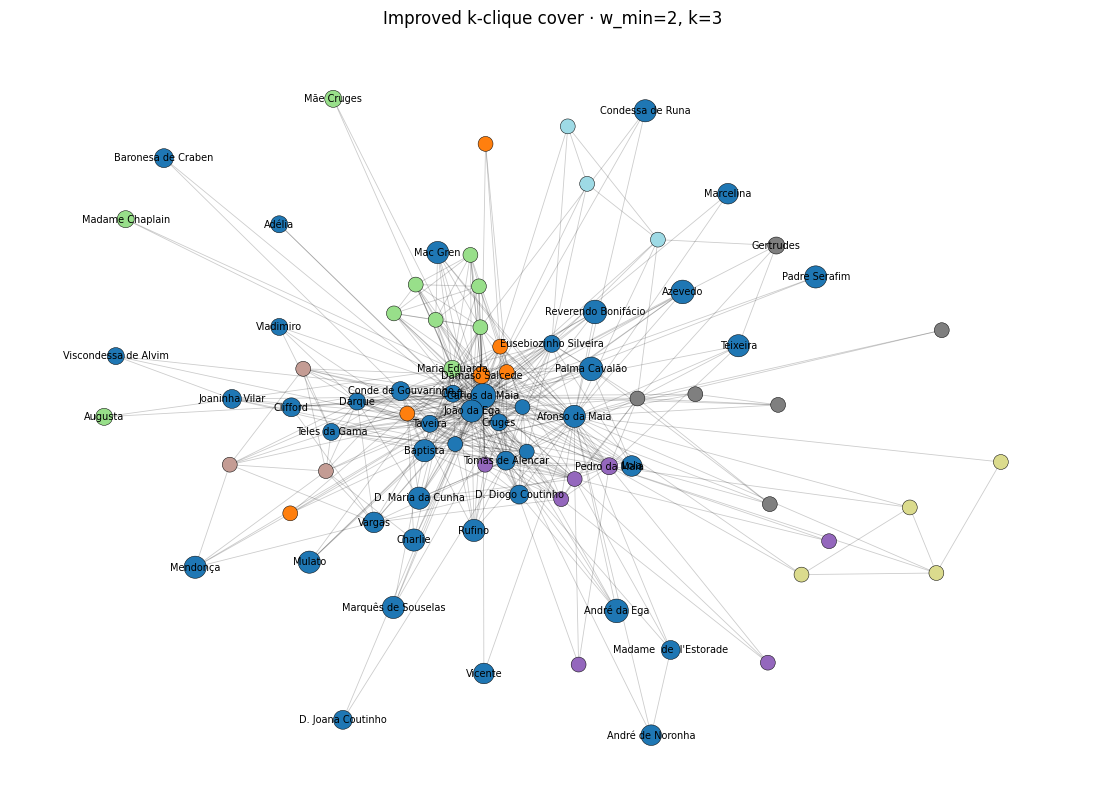

In [20]:
H = threshold_graph(G, BEST_W)
cover = best_result["cover"]
core = best_result["core"]
membership_count = defaultdict(int)
for c in cover:
    for node in c:
        membership_count[node] += 1

# Show the largest communities and their induced subgraph.
top_n = min(8, len(cover))
selected = cover[:top_n]
shown_nodes = set().union(*selected) if selected else set()
V = H.subgraph(shown_nodes).copy()
pos = nx.spring_layout(V, seed=42, weight="weight", k=0.6, iterations=100)

palette = plt.cm.tab20(np.linspace(0,1,max(1,top_n)))
node_colors = []
for node in V:
    memberships = [i for i,c in enumerate(selected) if node in c]
    node_colors.append(palette[memberships[0]] if memberships else (0.75,0.75,0.75,1))
node_sizes = [80 + 35*membership_count[n] for n in V]
fig, ax = plt.subplots(figsize=(14,10))
nx.draw_networkx_edges(V, pos, ax=ax, alpha=.20, width=.6)
nx.draw_networkx_nodes(V, pos, ax=ax, node_color=node_colors, node_size=node_sizes,
                       edgecolors="black", linewidths=.35)
labels = {n:name_map.get(n,n) for n in V if membership_count[n] > 1}
nx.draw_networkx_labels(V, pos, labels=labels, font_size=7, ax=ax)
ax.set_title(f"Improved k-clique cover · w_min={BEST_W}, k={BEST_K}")
ax.axis("off")
plt.show()

## 8. Sensitivity to edge deletion

This is a compact robustness check: randomly remove a fraction of edges and rerun the same settings. Agreement is measured with overlapping NMI on the original node universe. Low stability means the detected cover is sensitive to small perturbations.

In [21]:
def perturbation_stability(G, run_cover, reference, rounds=5,
                           drop_fraction=0.10, seed=7):
    rng = np.random.default_rng(seed)
    edges = list(G.edges(data=True))
    nodes = list(G.nodes)
    scores = []
    for _ in range(rounds):
        keep = rng.random(len(edges)) >= drop_fraction
        H = nx.Graph()
        H.add_nodes_from(G.nodes(data=True))
        H.add_edges_from((u,v,d) for (u,v,d), flag in zip(edges,keep) if flag)
        scores.append(overlapping_nmi(reference, run_cover(H), nodes))
    return float(np.mean(scores)), float(np.std(scores))

def run_best(H):
    H = threshold_graph(H, BEST_W)
    return improved_kclique(
        H, BEST_K, min_intensity=BEST_INTENSITY,
        weight_mode=WEIGHT_MODE, hierarchical=True,
        max_giant_fraction=0.50, attach_periphery=True,
    )["cover"]

stability_mean, stability_std = perturbation_stability(
    G, run_best, best_result["cover"], rounds=5, drop_fraction=0.10, seed=4207
)
print(f"10% edge-drop stability: {stability_mean:.3f} ± {stability_std:.3f}")

10% edge-drop stability: 0.582 ± 0.024


In [22]:
community_character_table = (
    membership.groupby("community")["character"]
    .agg(lambda names: ", ".join(sorted(set(names), key=str.casefold)))
    .reset_index()
    .rename(columns={
        "community": "community_id",
        "character": "characters"
    })
)
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(community_character_table)

,community_id,characters
0,1,"Adélia, Afonso da Maia, André da Ega, André de Noronha, Azevedo, Baptista, Baronesa de Craben, Carlos da Maia, Charlie, Clifford, Conde de Gouvarinho, Condessa de Runa, Craft, Cruges, D. Diogo Coutinho, D. Joana Coutinho, D. Maria da Cunha, Darque, Eusebiozinho Silveira, Joaninha Vilar, João da Ega, Lola, Mac Gren, Madame de l'Estorade, Marcelina, Marquês de Souselas, Mendonça, Mulato, Padre Serafim, Palma Cavalão, Reverendo Bonifácio, Rufino, Sequeira, Steinbroken, Taveira, Teixeira, Teles da Gama, Tomás de Alencar, Vargas, Vicente, Vilaça Júnior, Viscondessa de Alvim, Vladimiro"
1,2,"Adélia, Afonso da Maia, André da Ega, André de Noronha, Azevedo, Baptista, Baronesa de Craben, Carlos da Maia, Charlie, Clifford, Conde de Gouvarinho, Condessa de Gouvarinho, Condessa de Runa, Craft, Cruges, D. Diogo Coutinho, D. Joana Coutinho, D. Maria da Cunha, Dâmaso Salcede, Jacob Cohen, Joaninha Vilar, João da Ega, Lola, Mac Gren, Madame de l'Estorade, Madame Rughel, Marcelina, Marquês de Souselas, Mendonça, Mulato, Padre Serafim, Palma Cavalão, Raquel Cohen, Reverendo Bonifácio, Rufino, Taveira, Teixeira, Tomás de Alencar, Vargas, Vicente, Viscondessa de Alvim, Vítor"
2,3,"André da Ega, Augusta, Azevedo, Baptista, Carlos da Maia, Charlie, Clifford, Condessa de Runa, D. Maria da Cunha, Domingos, Dâmaso Salcede, Joaquim Álvares de Castro Gomes, João da Ega, Lola, Mac Gren, Madame Chaplain, Maria Eduarda, Marquês de Souselas, Melanie, Mendonça, Miss Sara, Mulato, Mãe Cruges, Niniche, Padre Serafim, Palma Cavalão, Reverendo Bonifácio, Rosa, Rufino"
3,4,"Afonso da Maia, André da Ega, André de Noronha, Augusta, Azevedo, Baptista, Carlos da Maia, Charlie, Condessa de Runa, D. Diogo Coutinho, D. Joana Coutinho, D. João da Cunha, D. Maria da Cunha, Guimarães, Joaninha Vilar, João da Ega, Mac Gren, Madame de l'Estorade, Madame Chaplain, Manuel Monforte, Marcelina, Maria Eduarda, Maria Monforte, Marquês de Souselas, Melo, Mendonça, Mulato, Mãe Cruges, Padre Serafim, Palma Cavalão, Pedro da Maia, Reverendo Bonifácio, Rufino, Tancredo, Teixeira, Tomás de Alencar, Vargas, Vicente"
4,5,"André da Ega, Azevedo, Baptista, Baronesa de Craben, Carlos da Maia, Charlie, Conde de Gouvarinho, D. Maria da Cunha, Darque, Gonçalo, João da Ega, Mac Gren, Marquês de Souselas, Mendonça, Mulato, Neves, Padre Serafim, Palma Cavalão, Reverendo Bonifácio, Rufino, Sousa Neto, Teles da Gama, Vargas, Vladimiro"
5,6,"abade Custódio, Afonso da Maia, André da Ega, André de Noronha, Azevedo, Brown, Carlos da Maia, Condessa de Runa, Esteves, Gertrudes, Marcelina, Reverendo Bonifácio, Saldanha, Teixeira, Vicente, Vilaça"
6,7,"Afonso da Maia, Conde de Runa, Maria Eduarda Runa, Padre Vasques, Pedro da Maia, Teixeira, Tia Fanny"
7,8,"Carlos da Maia, D. Ana Silveira, D. Eugénia Silveira, Eusebiozinho Silveira, Gertrudes, Lola, Palma Cavalão, Teresinha Silveira"


## 9. Export results

CSVs are written to an `improved_kclique_outputs` folder next to the notebook's working directory.

In [23]:
OUTPUT_DIR = Path.cwd() / "improved_kclique_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
sweep.to_csv(OUTPUT_DIR / "improved_kclique_sweep.csv", index=False)
membership.to_csv(OUTPUT_DIR / "improved_kclique_memberships.csv", index=False)
community_sizes.to_csv(OUTPUT_DIR / "improved_kclique_community_sizes.csv", index=False)
print("Saved outputs to:", OUTPUT_DIR.resolve())

Saved outputs to: C:\Users\lenovo\OneDrive\Documentos\Uni\DTU - Master in Business Analytics\Social Graphs\SGI-Project\improved_kclique_outputs


## 10. Interpretation checklist

- Does the result contain several communities rather than one giant cover?
- How many characters are covered by clique cores, and how many only by peripheral attachment?
- Which characters overlap, and do their links plausibly connect different social contexts?
- Does the interpretation survive a small edge perturbation?
- Do the conclusions change substantially with `k`, the edge threshold or clique intensity?

**Important:** a high score or a visually coherent group is not, by itself, evidence that the characters form a meaningful group in the novel. Check the source passages and the definition of co-occurrence.

In [24]:
sweep

,communities,coverage_pct,overlap_nodes,mean_memberships,largest_size,giant_fraction,method,w_min,k,min_intensity,EQ,ONMI_vs_Louvain,core_communities,periphery_nodes,hierarchical_splits
0,1,95.145631,0,1.000000,98,1.000000,baseline,1,3,NaN,-0.000004,0.031154,NaN,NaN,NaN
1,5,95.145631,46,1.693878,77,0.785714,improved,1,3,0.00,0.119845,0.174669,5.0,46.0,4.0
2,5,95.145631,46,1.693878,77,0.785714,improved,1,3,0.75,0.119845,0.174669,5.0,46.0,4.0
3,5,95.145631,46,1.693878,77,0.785714,improved,1,3,1.25,0.119845,0.174669,5.0,47.0,4.0
4,2,89.320388,2,1.021739,88,0.956522,baseline,1,4,NaN,0.017071,0.098522,NaN,NaN,NaN
5,5,95.145631,46,1.693878,77,0.785714,improved,1,4,0.00,0.119845,0.174669,5.0,46.0,3.0
6,5,95.145631,46,1.693878,77,0.785714,improved,1,4,0.75,0.119845,0.174669,5.0,46.0,3.0
7,5,95.145631,46,1.693878,77,0.785714,improved,1,4,1.25,0.119845,0.174669,5.0,47.0,3.0
8,2,72.815534,2,1.026667,72,0.960000,baseline,1,5,NaN,0.017712,0.095887,NaN,NaN,NaN
9,5,95.145631,46,1.693878,77,0.785714,improved,1,5,0.00,0.119845,0.174669,5.0,47.0,3.0
